# Exploratory Data Analysis: MM-Graph node-classification datasets

**Project:** Layer-wise Cross-Modal Fusion in Graph Neural Networks for Multimodal Node Classification

This notebook analyses the two node-classification datasets of the MM-Graph benchmark (Zhu et al., CVPR 2025),
**Ele-Fashion** and **Goodreads-NC**, with questions that matter for designing a multimodal GNN:

1. **Overview:** how large are the graphs and the feature vectors?
2. **Classes:** how balanced are the classes? (Decides whether macro-F1 is needed besides accuracy.)
3. **Graph structure:** how much neighborhood information does a node have?
4. **Homophily:** do connected nodes share a class, and for which classes does the graph help?
5. **Modalities:** are text and image features on the same scale, are they aligned, and how much class information
   does each carry on its own?
6. **Neighborhood signal per modality:** does the graph connect nodes that are similar in text, in images, or both?

Every figure is saved as PNG (300 dpi) and every table as CSV in `eda_outputs/`.

## 0. Setup

In [1]:
import os, gc, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.exceptions import ConvergenceWarning
from scipy import stats
import warnings

# ---- paths: change DATA_DIR if your datasets are elsewhere
DATA_DIR = os.path.expanduser("~/mm-graph-benchmark/data")
OUT_DIR = "eda_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

DATASETS = {"ele-fashion": "Ele-Fashion", "books-nc": "Goodreads-NC"}
ENCODERS = {"clip": "CLIP", "imagebind": "ImageBind", "t5vit": "T5 + ViT", "t5dino": "T5 + DINOv2"}

SEED = 0
PROBE_TRAIN, PROBE_TEST = 20000, 10000   # nodes used for the linear probes (sampled from the splits)
PAIR_SAMPLE = 20000                      # node pairs / edges sampled for similarity statistics
TSNE_SAMPLE = 3000                       # nodes per t-SNE plot

rng = np.random.default_rng(SEED)
random.seed(SEED)
COL_W = 3.5   # one column of an IEEE two-column paper, in inches
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300, "font.size": 8, "axes.titlesize": 8.5,
                     "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7})

def save_fig(fig, name):
    path = os.path.join(OUT_DIR, f"{name}.png")
    fig.savefig(path, bbox_inches="tight")
    print("saved", path)

def save_table(df, name):
    path = os.path.join(OUT_DIR, f"{name}.csv")
    df.to_csv(path, index=False)
    print("saved", path)

## 1. Loading the data

Each dataset folder contains the edge list, the labels (`labels-w-missing.pt`, where some nodes have no label), the
train/validation/test split, and one feature file per encoder. Every feature vector is the **text half followed by the
image half**, so it is split at its midpoint.

In [2]:
def to_numpy(x):
    """torch tensor / list / array -> numpy array (float tensors become float32)."""
    if hasattr(x, "numpy"):
        x = x.float() if x.is_floating_point() else x
        x = x.numpy()
    return np.asarray(x)

def load_graph(name):
    root = os.path.join(DATA_DIR, name)
    edges = to_numpy(torch.load(os.path.join(root, "nc_edges-nodeid.pt"))).astype(np.int64)
    if edges.shape[0] == 2 and edges.shape[1] != 2:      # accept a 2 x E layout as well
        edges = edges.T
    labels = to_numpy(torch.load(os.path.join(root, "labels-w-missing.pt"))).astype(np.int64)
    split = {k: to_numpy(v).astype(np.int64) for k, v in torch.load(os.path.join(root, "split.pt")).items()}
    n = labels.shape[0]

    # undirected simple graph: drop self-loops and duplicates, keep each edge once (u < v)
    u, v = edges[:, 0], edges[:, 1]
    keep = u != v
    u, v = np.minimum(u[keep], v[keep]), np.maximum(u[keep], v[keep])
    key = np.unique(u * n + v)
    eu, ev = key // n, key % n

    in_split = np.zeros(n, dtype=bool)
    for k in ("train_idx", "val_idx", "test_idx"):
        in_split[split[k]] = True
    labeled = (labels >= 0) & in_split
    return {"name": name, "n": n, "raw_edges": len(edges), "eu": eu, "ev": ev,
            "labels": labels, "labeled": labeled, "split": split}

def load_features(name, enc):
    x = to_numpy(torch.load(os.path.join(DATA_DIR, name, f"{enc}_feat.pt"), map_location="cpu")).astype(np.float32)
    half = x.shape[1] // 2
    return x[:, :half], x[:, half:]          # text, image

graphs = {}
for name in DATASETS:
    graphs[name] = load_graph(name)
    g = graphs[name]
    print(f"{DATASETS[name]}: {g['n']:,} nodes, {g['raw_edges']:,} edges in file, "
          f"{len(g['eu']):,} unique undirected edges")

Ele-Fashion: 97,766 nodes, 199,602 edges in file, 199,586 unique undirected edges
Goodreads-NC: 685,294 nodes, 7,235,048 edges in file, 6,841,179 unique undirected edges


## 2. Dataset overview

In [3]:
rows = []
for name, g in graphs.items():
    deg = np.bincount(np.concatenate([g["eu"], g["ev"]]), minlength=g["n"])
    y = g["labels"][g["labeled"]]
    dims = {}
    for enc in ENCODERS:
        path = os.path.join(DATA_DIR, name, f"{enc}_feat.pt")
        if os.path.exists(path):
            t, i = load_features(name, enc)
            dims[ENCODERS[enc]] = f"{t.shape[1]} + {i.shape[1]}"
            del t, i; gc.collect()
    rows.append({"Dataset": DATASETS[name], "Nodes": g["n"], "Undirected edges": len(g["eu"]),
                 "Average degree": round(deg.mean(), 2), "Classes": len(np.unique(y)),
                 "Train": len(g["split"]["train_idx"]), "Validation": len(g["split"]["val_idx"]),
                 "Test": len(g["split"]["test_idx"]), "Unlabeled nodes": int(g["n"] - g["labeled"].sum()),
                 **{f"Dim ({k})": v for k, v in dims.items()}})
overview = pd.DataFrame(rows)
save_table(overview, "table1_overview")
overview.T

saved eda_outputs/table1_overview.csv


,0,1
Dataset,Ele-Fashion,Goodreads-NC
Nodes,97766,685294
Undirected edges,199586,6841179
Average degree,4.08,19.97
Classes,11,10
Train,58659,406689
Validation,9777,67805
Test,29330,203428
Unlabeled nodes,0,7372
Dim (CLIP),512 + 512,512 + 512


## 3. Class distribution

If some classes are much larger than others, accuracy can look good while small classes are poorly predicted.
The imbalance ratio is the size of the largest class divided by the size of the smallest.

Ele-Fashion: 11 classes | largest 27,158 | smallest 499 | imbalance ratio 54.4 | largest class share 27.8%
Goodreads-NC: 10 classes | largest 204,380 | smallest 8,051 | imbalance ratio 25.4 | largest class share 30.1%
saved eda_outputs/fig1_class_distribution.png


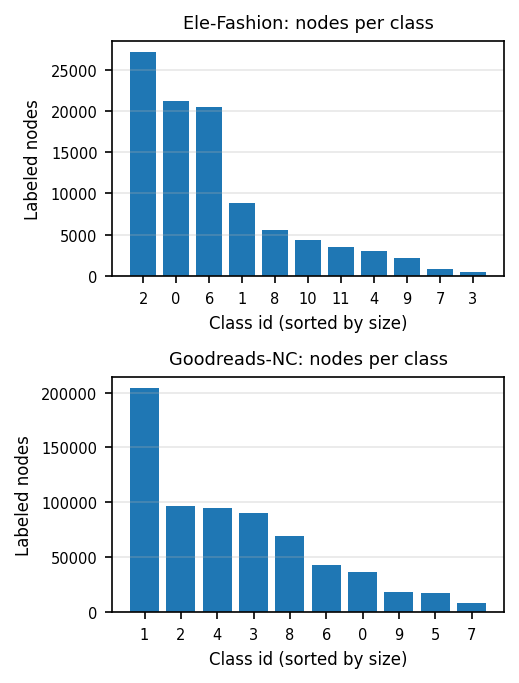

saved eda_outputs/table2_class_distribution.csv


In [4]:
fig, axes = plt.subplots(len(graphs), 1, figsize=(COL_W, 2.3 * len(graphs)))
axes = np.atleast_1d(axes)
class_rows = []
for ax, (name, g) in zip(axes, graphs.items()):
    y = g["labels"][g["labeled"]]
    classes, counts = np.unique(y, return_counts=True)
    order = np.argsort(-counts)
    share = counts / counts.sum()
    ax.bar(range(len(classes)), counts[order], color="tab:blue")
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes[order])
    ax.set(title=f"{DATASETS[name]}: nodes per class", xlabel="Class id (sorted by size)", ylabel="Labeled nodes")
    ax.grid(axis="y", alpha=0.3)
    for c, k, s in zip(classes, counts, share):
        class_rows.append({"Dataset": DATASETS[name], "Class": int(c), "Nodes": int(k), "Share (%)": round(100 * s, 2)})
    print(f"{DATASETS[name]}: {len(classes)} classes | largest {counts.max():,} | smallest {counts.min():,} | "
          f"imbalance ratio {counts.max() / counts.min():.1f} | largest class share {100 * share.max():.1f}%")
fig.tight_layout()
save_fig(fig, "fig1_class_distribution")
plt.show()
save_table(pd.DataFrame(class_rows), "table2_class_distribution")

## 4. Graph structure

The degree of a node is its number of neighbors. Nodes with very few neighbors get little information from the graph,
so a GNN (and any fusion inside it) can help them less.

saved eda_outputs/fig2_degree_distribution.png


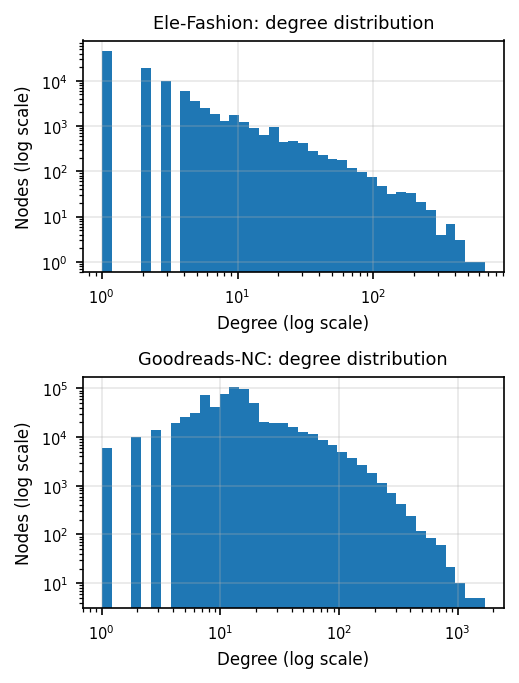

saved eda_outputs/table3_graph_structure.csv


,Dataset,Mean degree,Median degree,Max degree,Isolated nodes,Nodes with degree <= 2 (%),Connected components,Largest component (%)
0,Ele-Fashion,4.08,2,661,3,65.74,3279,88.69
1,Goodreads-NC,19.97,13,1698,0,2.32,12,99.99


In [5]:
fig, axes = plt.subplots(len(graphs), 1, figsize=(COL_W, 2.3 * len(graphs)))
axes = np.atleast_1d(axes)
struct_rows = []
for ax, (name, g) in zip(axes, graphs.items()):
    n = g["n"]
    deg = np.bincount(np.concatenate([g["eu"], g["ev"]]), minlength=n)
    adj = coo_matrix((np.ones(len(g["eu"])), (g["eu"], g["ev"])), shape=(n, n))
    n_comp, comp = connected_components(adj, directed=False)
    largest = np.bincount(comp).max()
    struct_rows.append({"Dataset": DATASETS[name], "Mean degree": round(deg.mean(), 2), "Median degree": int(np.median(deg)),
                        "Max degree": int(deg.max()), "Isolated nodes": int((deg == 0).sum()),
                        "Nodes with degree <= 2 (%)": round(100 * (deg <= 2).mean(), 2),
                        "Connected components": int(n_comp), "Largest component (%)": round(100 * largest / n, 2)})
    d = deg[deg > 0]
    bins = np.logspace(0, np.log10(d.max() + 1), 40)
    ax.hist(d, bins=bins, color="tab:blue")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(title=f"{DATASETS[name]}: degree distribution", xlabel="Degree (log scale)", ylabel="Nodes (log scale)")
    ax.grid(alpha=0.3)
fig.tight_layout()
save_fig(fig, "fig2_degree_distribution")
plt.show()
structure = pd.DataFrame(struct_rows)
save_table(structure, "table3_graph_structure")
structure

## 5. Homophily: do connected nodes share a class?

**Edge homophily** is the fraction of edges whose two (labeled) endpoints have the same class. GNNs work best when it is
high. **Per-class homophily** shows, for nodes of each class, the fraction of their labeled neighbors in the same class.
The last plot shows how a node's agreement with its neighbors changes with its degree.

saved eda_outputs/fig3_homophily.png


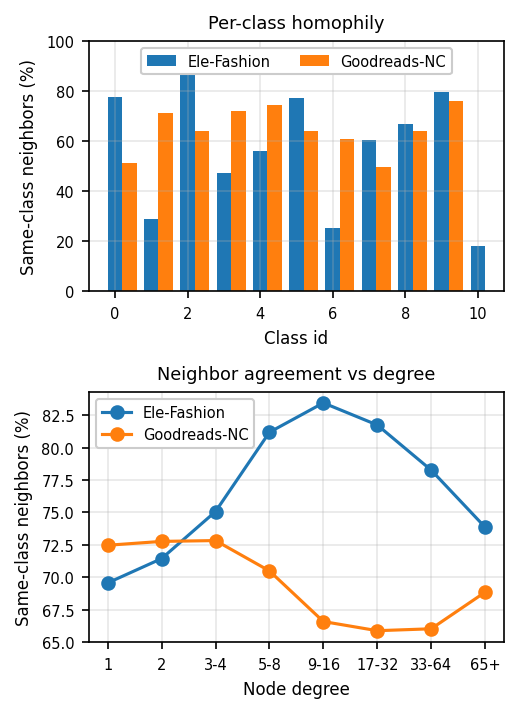

saved eda_outputs/table4_homophily.csv
saved eda_outputs/table5_per_class_homophily.csv


,Dataset,Edge homophily,Edges with both ends labeled (%)
0,Ele-Fashion,0.7675,100.00
1,Goodreads-NC,0.6758,98.38


In [6]:
homo_rows, perclass_rows = [], []
fig, axes = plt.subplots(2, 1, figsize=(COL_W, 4.8))
deg_bins = [1, 2, 3, 5, 9, 17, 33, 65, 10**9]
deg_labels = ["1", "2", "3-4", "5-8", "9-16", "17-32", "33-64", "65+"]
for name, g in graphs.items():
    y, lab = g["labels"], g["labeled"]
    src = np.concatenate([g["eu"], g["ev"]]); dst = np.concatenate([g["ev"], g["eu"]])   # both directions
    both = lab[src] & lab[dst]
    s, d = src[both], dst[both]
    same = (y[s] == y[d]).astype(float)
    homo_rows.append({"Dataset": DATASETS[name], "Edge homophily": round(same.mean(), 4),
                      "Edges with both ends labeled (%)": round(100 * both.mean(), 2)})
    # per class (source node's class)
    for c in np.unique(y[lab]):
        m = y[s] == c
        perclass_rows.append({"Dataset": DATASETS[name], "Class": int(c), "Same-class neighbors (%)": round(100 * same[m].mean(), 2)})
    # per node agreement vs degree
    agree_sum = np.bincount(s, weights=same, minlength=g["n"])
    agree_cnt = np.bincount(s, minlength=g["n"])
    deg = np.bincount(np.concatenate([g["eu"], g["ev"]]), minlength=g["n"])
    has = (agree_cnt > 0) & lab
    node_agree = agree_sum[has] / agree_cnt[has]
    bin_id = np.digitize(deg[has], deg_bins) - 1
    means = [node_agree[bin_id == b].mean() if (bin_id == b).any() else np.nan for b in range(len(deg_labels))]
    axes[1].plot(deg_labels, 100 * np.array(means), marker="o", label=DATASETS[name])

pc = pd.DataFrame(perclass_rows)
for k, (name, label) in enumerate(DATASETS.items()):
    sub = pc[pc.Dataset == label]
    axes[0].bar(np.arange(len(sub)) + 0.4 * k, sub["Same-class neighbors (%)"], width=0.4, label=label)
axes[0].set(title="Per-class homophily", xlabel="Class id", ylabel="Same-class neighbors (%)", ylim=(0, 100))
axes[1].set(title="Neighbor agreement vs degree", xlabel="Node degree", ylabel="Same-class neighbors (%)")
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper center", ncol=2, framealpha=1)
axes[1].legend(loc="best", framealpha=1)
fig.tight_layout()
save_fig(fig, "fig3_homophily")
plt.show()
homophily = pd.DataFrame(homo_rows)
save_table(homophily, "table4_homophily")
save_table(pc, "table5_per_class_homophily")
homophily

## 6. Modality analysis

For each encoder, three questions:

- **Scale:** are the text and image halves of the same size? If one is much larger, it can dominate a model that
  simply concatenates them.
- **Alignment:** is a node's own text–image pair more similar than a random text–image pair? Aligned encoders (CLIP,
  ImageBind) are trained to make this true; separately trained ones (T5 with ViT/DINOv2) are not.
- **Informativeness:** how well does a simple classifier (logistic regression, no graph) predict the class from the
  text only, the image only, and both together? This shows whether the modalities are complementary.

The same pass also measures the **neighborhood signal**: are connected nodes more similar than random pairs, in text
and in image?

In [7]:
def cosine_rows(a, b):
    a = a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-12)
    b = b / (np.linalg.norm(b, axis=1, keepdims=True) + 1e-12)
    return (a * b).sum(1)

def sample_split(idx, k):
    return idx if len(idx) <= k else rng.choice(idx, k, replace=False)

PROBE_MAX_ITER = 1000
convergence_warnings = []

def probe(x_tr, y_tr, x_te, y_te, tag):
    """Logistic regression on standardized features; returns accuracy, macro-F1 and the test predictions."""
    scaler = StandardScaler().fit(x_tr)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)
        clf = LogisticRegression(max_iter=PROBE_MAX_ITER).fit(scaler.transform(x_tr), y_tr)
    if any(issubclass(x.category, ConvergenceWarning) for x in w):
        convergence_warnings.append(tag)
    p = clf.predict(scaler.transform(x_te))
    return 100 * accuracy_score(y_te, p), 100 * f1_score(y_te, p, average="macro"), p

scale_rows, align_rows, probe_rows, nbr_rows = [], [], [], []
align_samples = {}      # (dataset, encoder) -> (own-pair cosines, random-pair cosines)
norm_samples = {}       # (dataset, encoder) -> (text norms, image norms), all nodes
nbr_samples = {}        # (dataset, encoder, modality) -> (connected cosines, random cosines)
probe_preds = {}        # (dataset, encoder, input) -> test predictions
probe_truth = {}        # dataset -> test labels used by the probes
for name, g in graphs.items():
    y = g["labels"]
    tr = sample_split(g["split"]["train_idx"][g["labeled"][g["split"]["train_idx"]]], PROBE_TRAIN)
    te = sample_split(g["split"]["test_idx"][g["labeled"][g["split"]["test_idx"]]], PROBE_TEST)
    nodes = rng.choice(g["n"], min(PAIR_SAMPLE, g["n"]), replace=False)
    perm = rng.permutation(nodes)
    e_idx = rng.choice(len(g["eu"]), min(PAIR_SAMPLE, len(g["eu"])), replace=False)
    eu, ev = g["eu"][e_idx], g["ev"][e_idx]
    ru, rv = rng.choice(g["n"], len(e_idx)), rng.choice(g["n"], len(e_idx))
    probe_truth[name] = y[te]
    for enc, enc_label in ENCODERS.items():
        if not os.path.exists(os.path.join(DATA_DIR, name, f"{enc}_feat.pt")):
            print(f"skip {name}/{enc}: file not found"); continue
        t, im = load_features(name, enc)
        nt, ni = np.linalg.norm(t, axis=1), np.linalg.norm(im, axis=1)
        norm_samples[(name, enc)] = (nt, ni)
        scale_rows.append({"Dataset": DATASETS[name], "Encoder": enc_label,
                           "Text norm (mean)": round(nt.mean(), 3), "Image norm (mean)": round(ni.mean(), 3),
                           "Image / text ratio": round(ni.mean() / nt.mean(), 2)})
        if t.shape[1] == im.shape[1]:
            own, rand = cosine_rows(t[nodes], im[nodes]), cosine_rows(t[nodes], im[perm])
            align_samples[(name, enc)] = (own, rand)
            align_rows.append({"Dataset": DATASETS[name], "Encoder": enc_label,
                               "Own pair cosine (mean)": round(own.mean(), 4), "Random pair cosine (mean)": round(rand.mean(), 4),
                               "Difference": round(own.mean() - rand.mean(), 4)})
        for mod, x in (("Text", t), ("Image", im)):
            con, rnd = cosine_rows(x[eu], x[ev]), cosine_rows(x[ru], x[rv])
            nbr_samples[(name, enc, mod)] = (con, rnd)
            nbr_rows.append({"Dataset": DATASETS[name], "Encoder": enc_label, "Modality": mod,
                             "Connected pairs (mean cosine)": round(con.mean(), 4),
                             "Random pairs (mean cosine)": round(rnd.mean(), 4)})
        both = np.concatenate([t, im], axis=1)
        for mod, x in (("Text only", t), ("Image only", im), ("Text + image", both)):
            acc, f1, pred = probe(x[tr], y[tr], x[te], y[te], f"{DATASETS[name]} | {enc_label} | {mod}")
            probe_preds[(name, enc, mod)] = pred
            probe_rows.append({"Dataset": DATASETS[name], "Encoder": enc_label, "Input": mod,
                               "Accuracy (%)": round(acc, 2), "Macro-F1 (%)": round(f1, 2)})
            print(f"{DATASETS[name]:13s} {enc_label:12s} {mod:13s} acc {acc:6.2f}  F1 {f1:6.2f}")
        del t, im, both; gc.collect()

print(f"\nLinear probes that did not converge within {PROBE_MAX_ITER} iterations: {len(convergence_warnings)}")
for t_ in convergence_warnings:
    print("  -", t_)
scale = pd.DataFrame(scale_rows); save_table(scale, "table6_feature_scale")
align = pd.DataFrame(align_rows); save_table(align, "table7_alignment")
probes = pd.DataFrame(probe_rows); save_table(probes, "table8_linear_probes")
nbr = pd.DataFrame(nbr_rows); save_table(nbr, "table9_neighborhood_similarity")
scale

Ele-Fashion   CLIP         Text only     acc  82.82  F1  67.99
Ele-Fashion   CLIP         Image only    acc  77.40  F1  60.18
Ele-Fashion   CLIP         Text + image  acc  80.41  F1  66.98
Ele-Fashion   ImageBind    Text only     acc  82.28  F1  67.77
Ele-Fashion   ImageBind    Image only    acc  79.71  F1  63.99
Ele-Fashion   ImageBind    Text + image  acc  79.58  F1  68.05
Ele-Fashion   T5 + ViT     Text only     acc  79.92  F1  65.92
Ele-Fashion   T5 + ViT     Image only    acc  75.38  F1  59.60
Ele-Fashion   T5 + ViT     Text + image  acc  77.42  F1  65.89
Ele-Fashion   T5 + DINOv2  Text only     acc  79.92  F1  65.92
Ele-Fashion   T5 + DINOv2  Image only    acc  77.78  F1  61.47
Ele-Fashion   T5 + DINOv2  Text + image  acc  78.39  F1  66.75
Goodreads-NC  CLIP         Text only     acc  61.83  F1  55.23
Goodreads-NC  CLIP         Image only    acc  54.72  F1  47.61
Goodreads-NC  CLIP         Text + image  acc  63.15  F1  56.94
Goodreads-NC  ImageBind    Text only     acc  32.42  F1

,Dataset,Encoder,Text norm (mean),Image norm (mean),Image / text ratio
0,Ele-Fashion,CLIP,1.000,1.000000,1.00
1,Ele-Fashion,ImageBind,100.000,1.000000,0.01
2,Ele-Fashion,T5 + ViT,3.649,19.091999,5.23
3,Ele-Fashion,T5 + DINOv2,3.649,29.415001,8.06
4,Goodreads-NC,CLIP,1.000,1.000000,1.00
5,Goodreads-NC,ImageBind,100.000,1.000000,0.01
6,Goodreads-NC,T5 + ViT,2.898,19.796000,6.83
7,Goodreads-NC,T5 + DINOv2,2.898,26.113001,9.01


### 6.1 Alignment between each node's text and image

,Dataset,Encoder,Own pair cosine (mean),Random pair cosine (mean),Difference
0,Ele-Fashion,CLIP,0.3047,0.1622,0.1425
1,Ele-Fashion,ImageBind,0.3272,0.0321,0.2951
2,Ele-Fashion,T5 + ViT,-0.0003,-0.0006,0.0003
3,Ele-Fashion,T5 + DINOv2,0.0042,0.0023,0.0019
4,Goodreads-NC,CLIP,0.2929,0.1653,0.1276
5,Goodreads-NC,ImageBind,0.0511,0.0252,0.0259
6,Goodreads-NC,T5 + ViT,0.0197,0.0194,0.0002
7,Goodreads-NC,T5 + DINOv2,0.0017,0.0024,-0.0006


saved eda_outputs/fig4_text_image_alignment.png


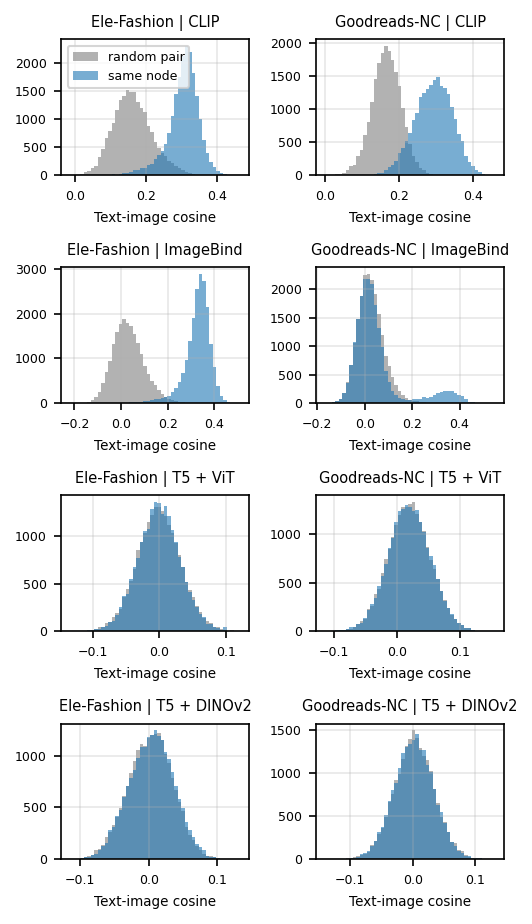

In [8]:
display(align)
keys = list(align_samples)
fig, axes = plt.subplots(len(ENCODERS), len(graphs), figsize=(COL_W, 1.55 * len(ENCODERS)), squeeze=False)
for r, name in enumerate(graphs):
    for c, enc in enumerate(ENCODERS):
        ax = axes[c, r]
        if (name, enc) not in align_samples:
            ax.axis("off"); continue
        own, rand = align_samples[(name, enc)]
        lo, hi = min(own.min(), rand.min()), max(own.max(), rand.max())
        bins = np.linspace(lo, hi, 50)
        ax.hist(rand, bins=bins, alpha=0.6, label="random pair", color="tab:gray")
        ax.hist(own, bins=bins, alpha=0.6, label="same node", color="tab:blue")
        ax.set_title(f"{DATASETS[name]} | {ENCODERS[enc]}", fontsize=7)
        ax.set_xlabel("Text-image cosine", fontsize=6.5); ax.tick_params(labelsize=6)
        ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=6)
fig.tight_layout()
save_fig(fig, "fig4_text_image_alignment")
plt.show()

### 6.2 How informative is each modality? (linear probes, no graph)

,Dataset,Encoder,Input,Accuracy (%),Macro-F1 (%)
0,Ele-Fashion,CLIP,Text only,82.82,67.99
1,Ele-Fashion,CLIP,Image only,77.40,60.18
2,Ele-Fashion,CLIP,Text + image,80.41,66.98
3,Ele-Fashion,ImageBind,Text only,82.28,67.77
4,Ele-Fashion,ImageBind,Image only,79.71,63.99
5,Ele-Fashion,ImageBind,Text + image,79.58,68.05
6,Ele-Fashion,T5 + ViT,Text only,79.92,65.92
7,Ele-Fashion,T5 + ViT,Image only,75.38,59.60
8,Ele-Fashion,T5 + ViT,Text + image,77.42,65.89
9,Ele-Fashion,T5 + DINOv2,Text only,79.92,65.92


saved eda_outputs/fig5_linear_probes.png


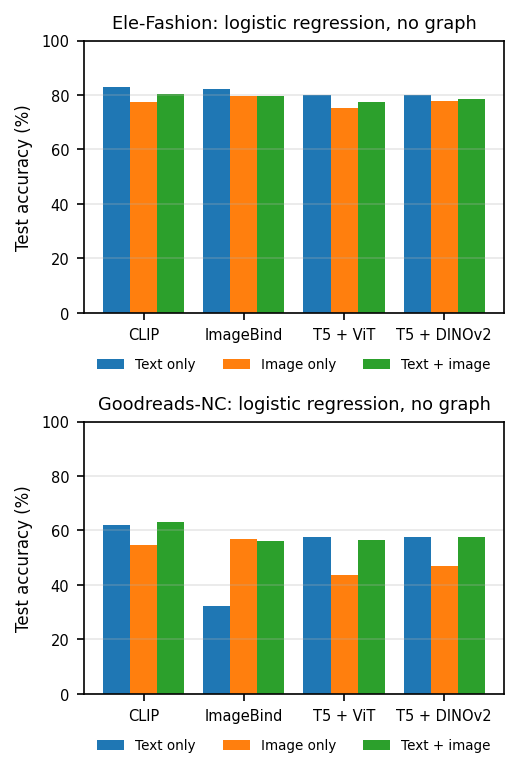

In [9]:
pivot = probes.pivot_table(index=["Dataset", "Encoder"], columns="Input", values="Accuracy (%)").reset_index()
display(probes)
fig, axes = plt.subplots(len(graphs), 1, figsize=(COL_W, 2.6 * len(graphs)))
axes = np.atleast_1d(axes)
inputs = ["Text only", "Image only", "Text + image"]
for ax, name in zip(axes, graphs):
    sub = probes[probes.Dataset == DATASETS[name]]
    encs = list(dict.fromkeys(sub.Encoder))
    for k, inp in enumerate(inputs):
        vals = [sub[(sub.Encoder == e) & (sub.Input == inp)]["Accuracy (%)"].values[0] for e in encs]
        ax.bar(np.arange(len(encs)) + 0.27 * (k - 1), vals, width=0.27, label=inp)
    ax.set_xticks(range(len(encs))); ax.set_xticklabels(encs)
    ax.set_ylim(0, 100)   # bars start at zero so differences are not exaggerated
    ax.set(title=f"{DATASETS[name]}: logistic regression, no graph", ylabel="Test accuracy (%)")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=6.5, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
fig.tight_layout()
save_fig(fig, "fig5_linear_probes")
plt.show()

### 6.3 Neighborhood signal per modality

,Dataset,Encoder,Modality,Connected pairs (mean cosine),Random pairs (mean cosine)
0,Ele-Fashion,CLIP,Text,0.7116,0.3954
1,Ele-Fashion,CLIP,Image,0.7540,0.6130
2,Ele-Fashion,ImageBind,Text,0.5832,0.2092
3,Ele-Fashion,ImageBind,Image,0.5862,0.3058
4,Ele-Fashion,T5 + ViT,Text,0.8043,0.6574
5,Ele-Fashion,T5 + ViT,Image,0.4542,0.1883
6,Ele-Fashion,T5 + DINOv2,Text,0.8043,0.6574
7,Ele-Fashion,T5 + DINOv2,Image,0.5636,0.2301
8,Goodreads-NC,CLIP,Text,0.6681,0.6004
9,Goodreads-NC,CLIP,Image,0.4955,0.4208


saved eda_outputs/fig6_neighborhood_similarity.png


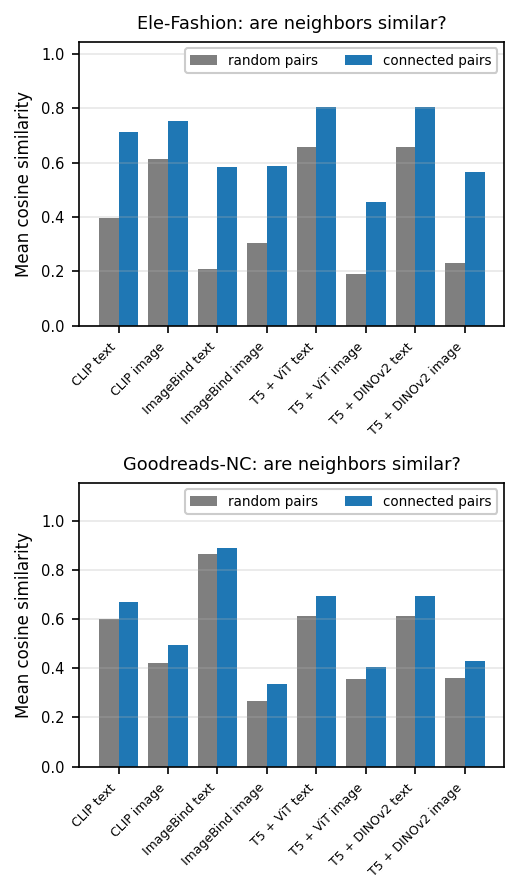

In [10]:
display(nbr)
fig, axes = plt.subplots(len(graphs), 1, figsize=(COL_W, 3.0 * len(graphs)))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, graphs):
    sub = nbr[nbr.Dataset == DATASETS[name]]
    labels_ = [f"{e} {m.lower()}" for e, m in zip(sub.Encoder, sub.Modality)]
    x = np.arange(len(sub))
    ax.bar(x - 0.2, sub["Random pairs (mean cosine)"], width=0.4, label="random pairs", color="tab:gray")
    ax.bar(x + 0.2, sub["Connected pairs (mean cosine)"], width=0.4, label="connected pairs", color="tab:blue")
    ax.set_xticks(x); ax.set_xticklabels(labels_, fontsize=6, rotation=45, ha="right")
    ax.set(title=f"{DATASETS[name]}: are neighbors similar?", ylabel="Mean cosine similarity")
    ax.grid(axis="y", alpha=0.3)
    top = max(sub["Connected pairs (mean cosine)"].max(), sub["Random pairs (mean cosine)"].max())
    ax.set_ylim(0, 1.3 * top)   # leave room for the legend above the bars
    ax.legend(fontsize=6.5, loc="upper right", ncol=2, framealpha=1)
fig.tight_layout()
save_fig(fig, "fig6_neighborhood_similarity")
plt.show()

## 7. Visualization (t-SNE, CLIP features)

Each point is a node, colored by its class. Well-separated colors mean the modality alone already distinguishes
the classes. A random sample of nodes is used to keep it fast.

saved eda_outputs/fig7_tsne_clip.png


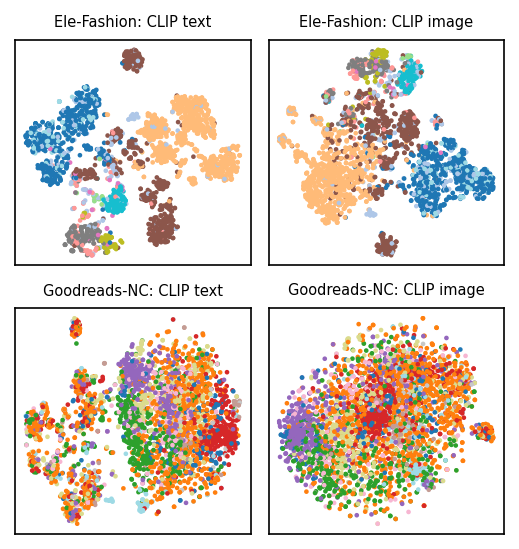

In [11]:
fig, axes = plt.subplots(len(graphs), 2, figsize=(COL_W, 1.85 * len(graphs)), squeeze=False)
for r, (name, g) in enumerate(graphs.items()):
    idx = np.where(g["labeled"])[0]
    idx = rng.choice(idx, min(TSNE_SAMPLE, len(idx)), replace=False)
    t, im = load_features(name, "clip")
    for c, (mod, x) in enumerate((("Text", t[idx]), ("Image", im[idx]))):
        z = PCA(n_components=50, random_state=SEED).fit_transform(StandardScaler().fit_transform(x))
        z = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(z)
        ax = axes[r, c]
        sc = ax.scatter(z[:, 0], z[:, 1], c=g["labels"][idx], cmap="tab20", s=1.5)
        ax.set_title(f"{DATASETS[name]}: CLIP {mod.lower()}", fontsize=7); ax.set_xticks([]); ax.set_yticks([])
    del t, im; gc.collect()
fig.tight_layout()
save_fig(fig, "fig7_tsne_clip")
plt.show()

## 8. Descriptive statistics and statistical tests

This section adds the standard EDA statistics and tests whether the patterns seen above are real.

**A note on p-values:** with tens of thousands of samples, almost any difference becomes "significant". Every test
therefore also reports an **effect size**: Cohen's d for differences in means (about 0.2 = small, 0.5 = medium,
0.8 = large), and Cramér's V for differences in proportions (below about 0.1 = negligible).

### 8.1 Descriptive statistics: node degree and feature norms

In [12]:
def describe(x):
    q1, med, q3 = np.percentile(x, [25, 50, 75])
    return {"Mean": round(float(np.mean(x)), 3), "Median": round(float(med), 3), "Std": round(float(np.std(x)), 3),
            "Min": round(float(np.min(x)), 3), "Q1": round(float(q1), 3), "Q3": round(float(q3), 3),
            "IQR": round(float(q3 - q1), 3), "Max": round(float(np.max(x)), 3), "Skewness": round(float(stats.skew(x)), 2)}

desc_rows = []
for name, g in graphs.items():
    deg = np.bincount(np.concatenate([g["eu"], g["ev"]]), minlength=g["n"])
    desc_rows.append({"Dataset": DATASETS[name], "Variable": "Node degree", **describe(deg)})
for (name, enc), (nt, ni) in norm_samples.items():
    desc_rows.append({"Dataset": DATASETS[name], "Variable": f"{ENCODERS[enc]} text norm", **describe(nt)})
    desc_rows.append({"Dataset": DATASETS[name], "Variable": f"{ENCODERS[enc]} image norm", **describe(ni)})
descriptive = pd.DataFrame(desc_rows)
save_table(descriptive, "table10_descriptive_statistics")
descriptive

saved eda_outputs/table10_descriptive_statistics.csv


/tmp/ipykernel_534/714702103.py:5: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  "IQR": round(float(q3 - q1), 3), "Max": round(float(np.max(x)), 3), "Skewness": round(float(stats.skew(x)), 2)}


,Dataset,Variable,Mean,Median,Std,Min,Q1,Q3,IQR,Max,Skewness
0,Ele-Fashion,Node degree,4.083,2.000,11.472,0.000,1.000,3.000,2.000,661.000,16.20
1,Goodreads-NC,Node degree,19.966,13.000,30.540,1.000,8.000,18.000,10.000,1698.000,8.90
2,Ele-Fashion,CLIP text norm,1.000,1.000,0.000,1.000,1.000,1.000,0.000,1.000,NaN
3,Ele-Fashion,CLIP image norm,1.000,1.000,0.000,1.000,1.000,1.000,0.000,1.000,NaN
4,Ele-Fashion,ImageBind text norm,100.000,100.000,0.000,100.000,100.000,100.000,0.000,100.000,NaN
5,Ele-Fashion,ImageBind image norm,1.000,1.000,0.000,1.000,1.000,1.000,0.000,1.000,NaN
6,Ele-Fashion,T5 + ViT text norm,3.649,3.644,0.223,2.721,3.503,3.786,0.283,5.086,0.25
7,Ele-Fashion,T5 + ViT image norm,19.092,19.044,1.022,14.125,18.364,19.816,1.451,23.885,0.10
8,Ele-Fashion,T5 + DINOv2 text norm,3.649,3.644,0.223,2.721,3.503,3.786,0.283,5.086,0.25
9,Ele-Fashion,T5 + DINOv2 image norm,29.415,29.277,3.218,18.089,27.061,31.715,4.653,41.897,0.10


### 8.2 Feature-norm distributions per modality (box plots)

saved eda_outputs/fig8_norm_boxplots.png


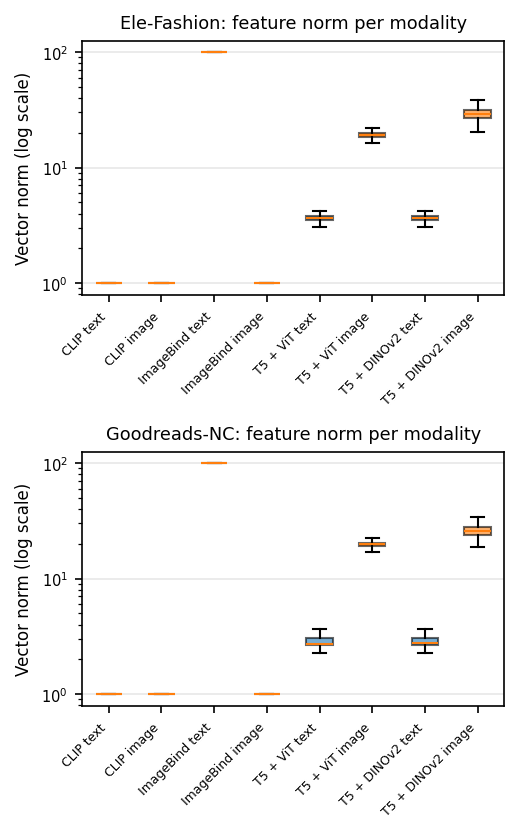

In [13]:
fig, axes = plt.subplots(len(graphs), 1, figsize=(COL_W, 2.8 * len(graphs)), squeeze=False)
for ax, name in zip(axes[:, 0], graphs):
    data, labels_, colors = [], [], []
    for enc in ENCODERS:
        if (name, enc) not in norm_samples:
            continue
        nt, ni = norm_samples[(name, enc)]
        pick = rng.choice(len(nt), min(PAIR_SAMPLE, len(nt)), replace=False)
        data += [nt[pick], ni[pick]]
        labels_ += [f"{ENCODERS[enc]}\ntext", f"{ENCODERS[enc]}\nimage"]
        colors += ["tab:blue", "tab:orange"]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False)
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c); patch.set_alpha(0.6)
    ax.set_xticks(range(1, len(labels_) + 1)); ax.set_xticklabels([l.replace("\n", " ") for l in labels_], fontsize=6, rotation=45, ha="right")
    ax.set_yscale("log")
    ax.set(title=f"{DATASETS[name]}: feature norm per modality", ylabel="Vector norm (log scale)")
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
save_fig(fig, "fig8_norm_boxplots")
plt.show()

### 8.3 Welch's t-test: alignment and neighborhood similarity

Welch's t-test compares two means without assuming equal variances. Two questions:
(a) is a node's own text–image pair more similar than a random pair (alignment)?
(b) are connected nodes more similar than random node pairs, per modality (neighborhood signal)?

In [14]:
def cohens_d(a, b):
    return (np.mean(a) - np.mean(b)) / np.sqrt((np.var(a, ddof=1) + np.var(b, ddof=1)) / 2)

def welch_row(a, b):
    t, p = stats.ttest_ind(a, b, equal_var=False)
    return {"Mean A": round(float(np.mean(a)), 4), "Mean B": round(float(np.mean(b)), 4),
            "Difference": round(float(np.mean(a) - np.mean(b)), 4), "t": round(float(t), 2),
            "p-value": float(p), "Cohen's d": round(float(cohens_d(a, b)), 3)}

align_tests = pd.DataFrame([{"Dataset": DATASETS[n], "Encoder": ENCODERS[e], "A": "own pair", "B": "random pair",
                             **welch_row(own, rnd)} for (n, e), (own, rnd) in align_samples.items()])
nbr_tests = pd.DataFrame([{"Dataset": DATASETS[n], "Encoder": ENCODERS[e], "Modality": m, "A": "connected", "B": "random",
                           **welch_row(con, rnd)} for (n, e, m), (con, rnd) in nbr_samples.items()])
save_table(align_tests, "table11_welch_alignment")
save_table(nbr_tests, "table12_welch_neighborhood")
pd.set_option("display.float_format", lambda v: f"{v:.3g}")
display(align_tests)
display(nbr_tests)

saved eda_outputs/table11_welch_alignment.csv
saved eda_outputs/table12_welch_neighborhood.csv


,Dataset,Encoder,A,B,Mean A,Mean B,Difference,t,p-value,Cohen's d
0,Ele-Fashion,CLIP,own pair,random pair,0.305,0.162,0.142,290,0,2.9
1,Ele-Fashion,ImageBind,own pair,random pair,0.327,0.0321,0.295,471,0,4.71
2,Ele-Fashion,T5 + ViT,own pair,random pair,-0.0003,-0.0006,0.0003,0.91,0.363,0.009
3,Ele-Fashion,T5 + DINOv2,own pair,random pair,0.0042,0.0023,0.0019,5.95,2.75e-09,0.059
4,Goodreads-NC,CLIP,own pair,random pair,0.293,0.165,0.128,283,0,2.83
5,Goodreads-NC,ImageBind,own pair,random pair,0.0511,0.0252,0.0259,29.4,1.35e-187,0.294
6,Goodreads-NC,T5 + ViT,own pair,random pair,0.0197,0.0194,0.0002,0.71,0.48,0.007
7,Goodreads-NC,T5 + DINOv2,own pair,random pair,0.0017,0.0024,-0.0006,-1.93,0.0534,-0.019


,Dataset,Encoder,Modality,A,B,Mean A,Mean B,Difference,t,p-value,Cohen's d
0,Ele-Fashion,CLIP,Text,connected,random,0.712,0.395,0.316,233,0,2.33
1,Ele-Fashion,CLIP,Image,connected,random,0.754,0.613,0.141,120,0,1.2
2,Ele-Fashion,ImageBind,Text,connected,random,0.583,0.209,0.374,250,0,2.5
3,Ele-Fashion,ImageBind,Image,connected,random,0.586,0.306,0.28,195,0,1.95
4,Ele-Fashion,T5 + ViT,Text,connected,random,0.804,0.657,0.147,163,0,1.63
5,Ele-Fashion,T5 + ViT,Image,connected,random,0.454,0.188,0.266,141,0,1.41
6,Ele-Fashion,T5 + DINOv2,Text,connected,random,0.804,0.657,0.147,163,0,1.63
7,Ele-Fashion,T5 + DINOv2,Image,connected,random,0.564,0.23,0.334,145,0,1.45
8,Goodreads-NC,CLIP,Text,connected,random,0.668,0.6,0.0677,66.8,0,0.668
9,Goodreads-NC,CLIP,Image,connected,random,0.495,0.421,0.0748,91.4,0,0.914


### 8.4 McNemar's test: does adding the image change the probe's predictions?

McNemar's test compares two classifiers on the **same** test nodes, using only the nodes where they disagree:
*b* = text-only correct but text + image wrong, *c* = the reverse. If *c* is much smaller than *b*, adding the image
makes the linear probe worse.

In [15]:
def mcnemar(y, pred_a, pred_b):
    a_ok, b_ok = pred_a == y, pred_b == y
    b = int(np.sum(a_ok & ~b_ok)); c = int(np.sum(~a_ok & b_ok))
    if b + c == 0:
        return b, c, np.nan, 1.0
    if b + c < 25:                                   # exact binomial version for few disagreements
        p = stats.binomtest(min(b, c), b + c, 0.5).pvalue
        return b, c, np.nan, float(p)
    chi2 = (abs(b - c) - 1) ** 2 / (b + c)           # with continuity correction
    return b, c, round(chi2, 2), float(stats.chi2.sf(chi2, 1))

mc_rows = []
for (name, enc, mod) in probe_preds:
    if mod != "Text only":
        continue
    y_te = probe_truth[name]
    for other in ("Text + image", "Image only"):
        b, c, chi2, p = mcnemar(y_te, probe_preds[(name, enc, "Text only")], probe_preds[(name, enc, other)])
        mc_rows.append({"Dataset": DATASETS[name], "Encoder": ENCODERS[enc], "Comparison": f"Text only vs {other}",
                        "Text only right, other wrong (b)": b, "Other right, text only wrong (c)": c,
                        "Chi2": chi2, "p-value": p})
mcnemar_table = pd.DataFrame(mc_rows)
save_table(mcnemar_table, "table13_mcnemar_probes")
mcnemar_table

saved eda_outputs/table13_mcnemar_probes.csv


,Dataset,Encoder,Comparison,"Text only right, other wrong (b)","Other right, text only wrong (c)",Chi2,p-value
0,Ele-Fashion,CLIP,Text only vs Text + image,692,451,50.4,1.26e-12
1,Ele-Fashion,CLIP,Text only vs Image only,1176,634,162,4.81e-37
2,Ele-Fashion,ImageBind,Text only vs Text + image,826,556,52.4,4.62e-13
3,Ele-Fashion,ImageBind,Text only vs Image only,1000,743,37.6,8.69e-10
4,Ele-Fashion,T5 + ViT,Text only vs Text + image,927,677,38.6,5.06e-10
5,Ele-Fashion,T5 + ViT,Text only vs Image only,1347,893,91.6,1.05e-21
6,Ele-Fashion,T5 + DINOv2,Text only vs Text + image,805,652,15.9,6.83e-05
7,Ele-Fashion,T5 + DINOv2,Text only vs Image only,1118,904,22.4,2.17e-06
8,Goodreads-NC,CLIP,Text only vs Text + image,904,1036,8.85,0.00294
9,Goodreads-NC,CLIP,Text only vs Image only,2119,1408,143,6.1e-33


### 8.5 Chi-square test: are class proportions the same in train, validation and test?

If the split preserves class proportions, the chi-square test finds no meaningful difference (small Cramér's V).

In [16]:
chi_rows = []
for name, g in graphs.items():
    y = g["labels"]
    classes = np.unique(y[g["labeled"]])
    table = []
    for k in ("train_idx", "val_idx", "test_idx"):
        idx = g["split"][k][g["labeled"][g["split"][k]]]
        table.append([np.sum(y[idx] == c) for c in classes])
    table = np.array(table)
    table = table[:, table.sum(0) > 0]
    chi2, p, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.sum() * (min(table.shape) - 1)))
    chi_rows.append({"Dataset": DATASETS[name], "Chi2": round(chi2, 2), "dof": dof, "p-value": p,
                     "Cramér's V": round(cramers_v, 4)})
chi_table = pd.DataFrame(chi_rows)
save_table(chi_table, "table14_chi_square_splits")
chi_table

saved eda_outputs/table14_chi_square_splits.csv


,Dataset,Chi2,dof,p-value,Cramér's V
0,Ele-Fashion,14.1,20,0.825,0.0085
1,Goodreads-NC,21.4,18,0.261,0.004


## 10. Data validation and dataset curation

Checks run on the **raw** files before any cleaning, to document data quality:

- **Splits:** are train, validation and test mutually exclusive? Any repeated node inside a split? Are all indices valid?
  Does every split node have a label, and do all classes appear in every split?
- **Labels:** value range and number of missing labels.
- **Edges:** self-loops, duplicate edges, and endpoints outside the valid node range.
- **Features:** one row per node, and no NaN, infinite, or all-zero vectors, for every encoder.

The result is saved as `table15_data_validation.csv`.

In [17]:
val_rows = []
def check(dataset, group, name, value, ok=None):
    status = "info" if ok is None else ("pass" if ok else "FAIL")
    val_rows.append({"Dataset": DATASETS[dataset], "Group": group, "Check": name, "Result": value, "Status": status})

for name in DATASETS:
    root = os.path.join(DATA_DIR, name)
    edges = to_numpy(torch.load(os.path.join(root, "nc_edges-nodeid.pt"))).astype(np.int64)
    if edges.shape[0] == 2 and edges.shape[1] != 2:
        edges = edges.T
    labels = to_numpy(torch.load(os.path.join(root, "labels-w-missing.pt"))).astype(np.int64)
    split = {k: to_numpy(v).astype(np.int64) for k, v in torch.load(os.path.join(root, "split.pt")).items()}
    n = len(labels)
    tr, va, te = split["train_idx"], split["val_idx"], split["test_idx"]

    # ---- splits
    check(name, "Splits", "Train / validation overlap (nodes)", len(np.intersect1d(tr, va)), len(np.intersect1d(tr, va)) == 0)
    check(name, "Splits", "Train / test overlap (nodes)", len(np.intersect1d(tr, te)), len(np.intersect1d(tr, te)) == 0)
    check(name, "Splits", "Validation / test overlap (nodes)", len(np.intersect1d(va, te)), len(np.intersect1d(va, te)) == 0)
    dups = sum(len(s) - len(np.unique(s)) for s in (tr, va, te))
    check(name, "Splits", "Repeated nodes inside a split", dups, dups == 0)
    allidx = np.concatenate([tr, va, te])
    check(name, "Splits", "Split indices within [0, N)", f"min {allidx.min()}, max {allidx.max()}, N {n}", allidx.min() >= 0 and allidx.max() < n)
    missing_in_split = int((labels[allidx] < 0).sum())
    check(name, "Splits", "Split nodes without a label", missing_in_split, missing_in_split == 0)
    in_split = np.zeros(n, bool); in_split[allidx] = True
    check(name, "Splits", "Nodes in no split", int((~in_split).sum()))
    sizes = [len(tr), len(va), len(te)]
    check(name, "Splits", "Split ratio (train / val / test)", " / ".join(f"{100 * s / sum(sizes):.1f}%" for s in sizes))
    cls_all = np.unique(labels[allidx][labels[allidx] >= 0])
    missing_cls = {k: sorted(set(cls_all) - set(np.unique(labels[s]))) for k, s in (("train", tr), ("val", va), ("test", te))}
    check(name, "Splits", "Classes missing from a split", (str({k: v for k, v in missing_cls.items() if v}) if any(missing_cls.values()) else "none"),
          all(len(v) == 0 for v in missing_cls.values()))

    # ---- labels
    valid = labels[labels >= 0]
    check(name, "Labels", "Label value range", f"{valid.min()} to {valid.max()}")
    check(name, "Labels", "Distinct classes among labeled nodes", len(np.unique(valid)))
    check(name, "Labels", "Nodes with missing label (< 0)", int((labels < 0).sum()))

    # ---- edges
    u, v = edges[:, 0], edges[:, 1]
    out_of_range = int(((u < 0) | (u >= n) | (v < 0) | (v >= n)).sum())
    check(name, "Edges", "Edges in file", len(edges))
    check(name, "Edges", "Endpoints outside [0, N)", out_of_range, out_of_range == 0)
    loops = int((u == v).sum())
    check(name, "Edges", "Self-loops (removed)", loops)
    a, b = np.minimum(u[u != v], v[u != v]), np.maximum(u[u != v], v[u != v])
    n_unique = len(np.unique(a * n + b))
    check(name, "Edges", "Duplicate or reverse-duplicate edges (removed)", int(len(a) - n_unique))
    check(name, "Edges", "Unique undirected edges after cleaning", n_unique)

    # ---- features
    for enc, enc_label in ENCODERS.items():
        path = os.path.join(root, f"{enc}_feat.pt")
        if not os.path.exists(path):
            continue
        x = to_numpy(torch.load(path, map_location="cpu")).astype(np.float32)
        check(name, "Features", f"{enc_label}: rows = number of nodes", f"{x.shape[0]} rows, {x.shape[1]} columns", x.shape[0] == n)
        n_nan, n_inf = int(np.isnan(x).sum()), int(np.isinf(x).sum())
        check(name, "Features", f"{enc_label}: NaN / Inf values", f"{n_nan} / {n_inf}", n_nan == 0 and n_inf == 0)
        half = x.shape[1] // 2
        zero_t = int((np.abs(x[:, :half]).sum(1) == 0).sum()); zero_i = int((np.abs(x[:, half:]).sum(1) == 0).sum())
        check(name, "Features", f"{enc_label}: all-zero text / image vectors", f"{zero_t} / {zero_i}", zero_t == 0 and zero_i == 0)
        del x; gc.collect()

validation = pd.DataFrame(val_rows)
save_table(validation, "table15_data_validation")
print(f"Checks: {len(validation)} | failed: {(validation.Status == 'FAIL').sum()}")
pd.set_option("display.max_colwidth", 80)
display(validation)

saved eda_outputs/table15_data_validation.csv
Checks: 58 | failed: 0


,Dataset,Group,Check,Result,Status
0,Ele-Fashion,Splits,Train / validation overlap (nodes),0,pass
1,Ele-Fashion,Splits,Train / test overlap (nodes),0,pass
2,Ele-Fashion,Splits,Validation / test overlap (nodes),0,pass
3,Ele-Fashion,Splits,Repeated nodes inside a split,0,pass
4,Ele-Fashion,Splits,"Split indices within [0, N)","min 0, max 97765, N 97766",pass
5,Ele-Fashion,Splits,Split nodes without a label,0,pass
6,Ele-Fashion,Splits,Nodes in no split,0,info
7,Ele-Fashion,Splits,Split ratio (train / val / test),60.0% / 10.0% / 30.0%,info
8,Ele-Fashion,Splits,Classes missing from a split,none,pass
9,Ele-Fashion,Labels,Label value range,0 to 11,info


## 11. Structural bias: degree by class

If some classes consist mostly of poorly connected nodes, a GNN systematically receives less neighborhood information for
them. This table shows, per class, the median degree and the share of nodes with at most 2 neighbors.

In [18]:
deg_rows = []
for name, g in graphs.items():
    deg = np.bincount(np.concatenate([g["eu"], g["ev"]]), minlength=g["n"])
    y, lab = g["labels"], g["labeled"]
    for c in np.unique(y[lab]):
        d = deg[lab & (y == c)]
        deg_rows.append({"Dataset": DATASETS[name], "Class": int(c), "Nodes": len(d), "Median degree": float(np.median(d)),
                         "Degree <= 2 (%)": round(100 * (d <= 2).mean(), 1)})
degree_by_class = pd.DataFrame(deg_rows)
save_table(degree_by_class, "table16_degree_by_class")
for ds in degree_by_class.Dataset.unique():
    sub = degree_by_class[degree_by_class.Dataset == ds]
    print(f"{ds}: median degree per class ranges {sub['Median degree'].min()}-{sub['Median degree'].max()}; "
          f"low-degree share ranges {sub['Degree <= 2 (%)'].min()}-{sub['Degree <= 2 (%)'].max()}%")
degree_by_class

saved eda_outputs/table16_degree_by_class.csv
Ele-Fashion: median degree per class ranges 1.0-2.0; low-degree share ranges 54.1-87.5%
Goodreads-NC: median degree per class ranges 11.0-16.0; low-degree share ranges 1.0-5.1%


,Dataset,Class,Nodes,Median degree,Degree <= 2 (%)
0,Ele-Fashion,0,21201,1,75.3
1,Ele-Fashion,1,8839,1,72.9
2,Ele-Fashion,2,27158,2,54.1
3,Ele-Fashion,3,499,1,75.2
4,Ele-Fashion,4,3004,1,72.1
5,Ele-Fashion,6,20525,2,60.3
6,Ele-Fashion,7,874,1,87.5
7,Ele-Fashion,8,5579,1,79.5
8,Ele-Fashion,9,2229,1,74.8
9,Ele-Fashion,10,4337,2,58.8


## 9. Summary of key numbers

A compact summary to use when writing the EDA section. Every table and figure above is also saved in `eda_outputs/`.

In [19]:
print("=== Overview ===");            print(overview.to_string(index=False))
print("\n=== Graph structure ===");   print(structure.to_string(index=False))
print("\n=== Homophily ===");         print(homophily.to_string(index=False))
print("\n=== Feature scale ===");     print(scale.to_string(index=False))
print("\n=== Alignment ===");         print(align.to_string(index=False))
print("\n=== Linear probes (accuracy %) ===")
print(probes.pivot_table(index=["Dataset", "Encoder"], columns="Input", values="Accuracy (%)").to_string())
print("\n=== Neighborhood similarity ==="); print(nbr.to_string(index=False))
print("\n=== Descriptive statistics ==="); print(descriptive.to_string(index=False))
print("\n=== Welch t-test: alignment ==="); print(align_tests.to_string(index=False))
print("\n=== Welch t-test: neighborhood ==="); print(nbr_tests.to_string(index=False))
print("\n=== McNemar: linear probes ==="); print(mcnemar_table.to_string(index=False))
print("\n=== Chi-square: class proportions across splits ==="); print(chi_table.to_string(index=False))
print(f"\nNon-converged probes: {len(convergence_warnings)}")

=== Overview ===
     Dataset  Nodes  Undirected edges  Average degree  Classes  Train  Validation   Test  Unlabeled nodes Dim (CLIP) Dim (ImageBind) Dim (T5 + ViT) Dim (T5 + DINOv2)
 Ele-Fashion  97766            199586            4.08       11  58659        9777  29330                0  512 + 512     1024 + 1024      768 + 768         768 + 768
Goodreads-NC 685294           6841179              20       10 406689       67805 203428             7372  512 + 512     1024 + 1024      768 + 768         768 + 768

=== Graph structure ===
     Dataset  Mean degree  Median degree  Max degree  Isolated nodes  Nodes with degree <= 2 (%)  Connected components  Largest component (%)
 Ele-Fashion         4.08              2         661               3                        65.7                  3279                   88.7
Goodreads-NC           20             13        1698               0                        2.32                    12                    100

=== Homophily ===
     Dataset  E